# Linguistic Marker Gender — GSM8K v1.2.1 (Candidate)

Notebook ini membaca **full run 71.215 respons**. Correctness tidak dipakai untuk memilih respons atau contrast. Semua visual masih berstatus kandidat sampai precision/recall audit dinilai dua penilai dan inter-rater agreement dilaporkan.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

REPO_ROOT = Path.cwd().resolve()
if REPO_ROOT.name.casefold() == 'notebooks':
    REPO_ROOT = REPO_ROOT.parent
RUN_DIR = REPO_ROOT / 'result' / 'linguistic_markers' / 'gender_gsm8k_full_source_aligned_v1_2_1_20260817'
SUMMARY_DIR = REPO_ROOT / 'result' / 'linguistic_markers' / 'gender_gsm8k_bab4_candidate_summary_v1_2_1_20260817'
FIG_DIR = SUMMARY_DIR / 'images'
FIG_DIR.mkdir(parents=True, exist_ok=True)

manifest = json.loads((RUN_DIR / 'manifest.json').read_text(encoding='utf-8'))
assert manifest['pipeline_version'] == 'gender-lm-v1.2.1-candidate'
assert manifest['response_records'] == 71_215
assert manifest['correctness_filter_applied'] is False

qc = pd.read_csv(RUN_DIR / 'quality_control.csv')
descriptives = pd.read_csv(RUN_DIR / 'condition_descriptives.csv')
numeric = pd.read_csv(RUN_DIR / 'paired_numeric.csv')
presence = pd.read_csv(RUN_DIR / 'paired_binary.csv')
openings = pd.read_csv(RUN_DIR / 'paired_openings.csv')
omnibus = pd.read_csv(RUN_DIR / 'omnibus.csv')
audit_hits = pd.read_csv(RUN_DIR / 'audit_marker_hits.csv')
audit_recall = pd.read_csv(RUN_DIR / 'audit_recall_responses.csv')

display(Markdown(f"**Run tervalidasi:** `{manifest['pipeline_version']}` — {manifest['response_records']:,} respons — {manifest['bootstrap_resamples']:,} bootstrap resample."))

**Run tervalidasi:** `gender-lm-v1.2.1-candidate` — 71,215 respons — 10,000 bootstrap resample.

## Validasi dan cakupan

Technical-only dan missing tetap tidak dianggap sebagai respons dengan marker nol.

In [2]:
coverage = (qc.groupby('model_id', as_index=False)
            .agg(n_records=('n_records', 'sum'),
                 n_text_available=('n_text_available', 'sum'),
                 n_missing_text=('n_missing_text', 'sum'),
                 n_technical_only=('n_technical_only', 'sum')))
coverage['n_not_linguistically_available'] = coverage['n_records'] - coverage['n_text_available']
display(coverage)

test_inventory = pd.DataFrame({
    'table': ['paired numeric', 'paired presence', 'paired openings', 'omnibus'],
    'planned_rows': [len(numeric), len(presence), len(openings), len(omnibus)],
    'holm_significant': [(numeric.p_holm < .05).sum(), (presence.p_holm < .05).sum(),
                         (openings.p_holm < .05).sum(), (omnibus.p_holm < .05).sum()]
})
display(test_inventory)
print('Precision audit rows:', len(audit_hits), '| markers represented:', audit_hits.marker_id.nunique())
print('Recall audit rows:', len(audit_recall), '| model-persona conditions:', audit_recall.groupby(['model_id','persona']).ngroups)

,model_id,n_records,n_text_available,n_missing_text,n_technical_only,n_not_linguistically_available
0,deepseek_deepseek-r1-distill-qwen-32b,11869,11722,147,0,147
1,meta-llama_llama-3.1-8b-instruct,11869,11868,1,0,1
2,meta-llama_llama-3.3-70b-instruct,11870,11859,11,0,11
3,mistralai_ministral-8b-2512,11869,11868,1,0,1
4,openai_gpt-oss-20b,11870,11063,5,802,807
5,qwen_qwen3-next-80b-a3b-thinking,11868,11868,0,0,0


,table,planned_rows,holm_significant
0,paired numeric,1596,612
1,paired presence,1428,439
2,paired openings,924,147
3,omnibus,372,157


Precision audit rows: 850 | markers represented: 17
Recall audit rows: 108 | model-persona conditions: 54


In [3]:
sns.set_theme(style='whitegrid', context='notebook')
MODEL_LABELS = {
    'meta-llama_llama-3.1-8b-instruct': 'Llama 3.1 8B',
    'meta-llama_llama-3.3-70b-instruct': 'Llama 3.3 70B',
    'mistralai_ministral-8b-2512': 'Ministral 8B',
    'deepseek_deepseek-r1-distill-qwen-32b': 'DeepSeek R1 32B',
    'openai_gpt-oss-20b': 'GPT-OSS 20B',
    'qwen_qwen3-next-80b-a3b-thinking': 'Qwen3 Next 80B',
}
MODEL_ORDER = list(MODEL_LABELS)

def save_figure(fig, filename):
    path = FIG_DIR / filename
    fig.savefig(path, dpi=220, bbox_inches='tight', facecolor='white')
    print('saved:', path.relative_to(REPO_ROOT))
    return path

## Gambar 1 — Coverage teks

Bagian merah muda adalah respons missing atau technical-only dan tidak masuk sebagai nol marker linguistik.

saved: result\linguistic_markers\gender_gsm8k_bab4_candidate_summary_v1_2_1_20260817\images\01_text_coverage_by_model.png


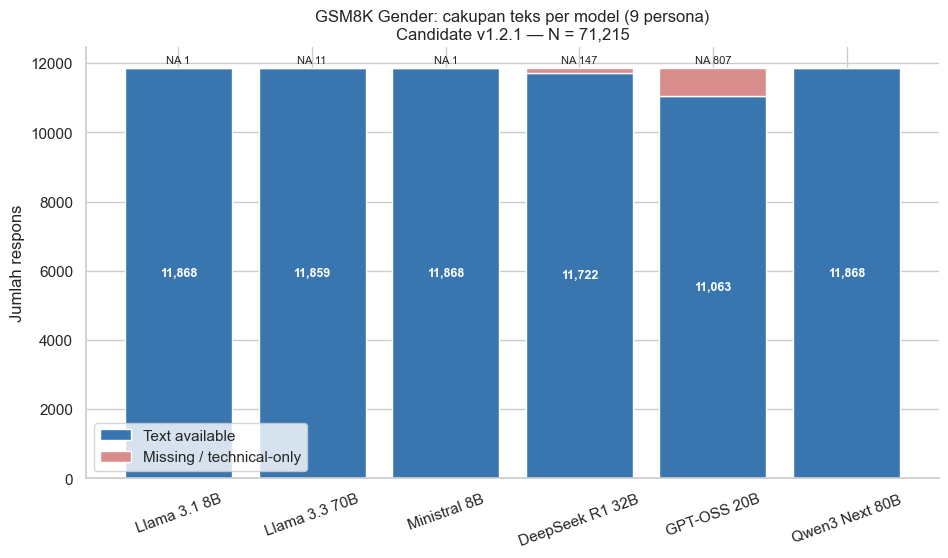

In [4]:
plot_cov = coverage.set_index('model_id').reindex(MODEL_ORDER).reset_index()
labels = plot_cov.model_id.map(MODEL_LABELS)
fig, ax = plt.subplots(figsize=(11, 5.6))
ax.bar(labels, plot_cov.n_text_available, color='#3976af', label='Text available')
ax.bar(labels, plot_cov.n_not_linguistically_available, bottom=plot_cov.n_text_available,
       color='#d98c8c', label='Missing / technical-only')
for i, row in plot_cov.iterrows():
    ax.text(i, row.n_text_available / 2, f"{int(row.n_text_available):,}",
            ha='center', va='center', color='white', fontsize=9, fontweight='bold')
    if row.n_not_linguistically_available:
        ax.text(i, row.n_text_available + row.n_not_linguistically_available + 80,
                f"NA {int(row.n_not_linguistically_available):,}", ha='center', va='bottom', fontsize=8)
ax.set_title('GSM8K Gender: cakupan teks per model (9 persona)\nCandidate v1.2.1 — N = 71,215')
ax.set_ylabel('Jumlah respons')
ax.set_xlabel('')
ax.tick_params(axis='x', rotation=20)
ax.legend(frameon=True, loc='lower left')
sns.despine(ax=ax)
save_figure(fig, '01_text_coverage_by_model.png')
plt.show()

## Gambar 2 — Explicit persona vs neutral: marker presence

Nilai adalah selisih prevalence dalam **percentage points** (explicit minus neutral). Titik hitam menandai exact McNemar `p_holm < 0.05`. Ini bukan perbandingan accuracy.

saved: result\linguistic_markers\gender_gsm8k_bab4_candidate_summary_v1_2_1_20260817\images\02_explicit_vs_neutral_marker_presence_heatmap.png


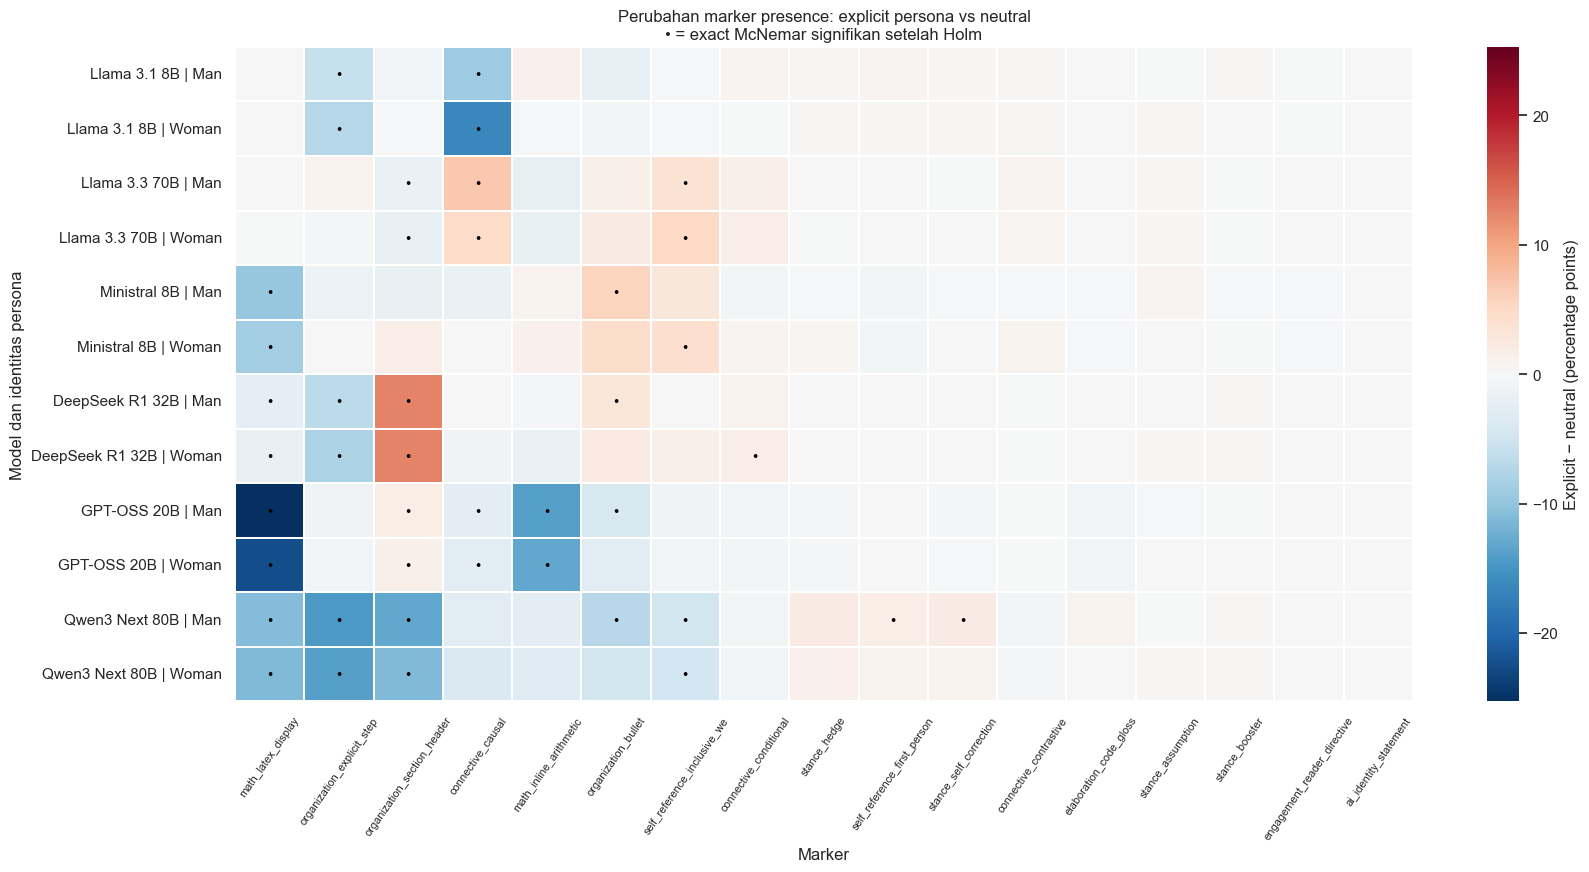

In [5]:
ep = presence[presence.contrast_id.eq('explicit_vs_neutral')].copy()
ep['row'] = ep.model_id.map(MODEL_LABELS) + ' | ' + ep.identity.str.title()
ep['delta_pp'] = 100 * ep.prevalence_delta
row_order = [f"{MODEL_LABELS[m]} | {identity.title()}" for m in MODEL_ORDER for identity in ('man','woman')]
outcome_order = ep.groupby('outcome_id').prevalence_delta.apply(lambda x: x.abs().mean()).sort_values(ascending=False).index.tolist()
heat = ep.pivot(index='row', columns='outcome_id', values='delta_pp').reindex(index=row_order, columns=outcome_order)
sig = ep.assign(sig=ep.p_holm.lt(.05)).pivot(index='row', columns='outcome_id', values='sig').reindex(index=row_order, columns=outcome_order)
limit = max(5, float(np.nanmax(np.abs(heat.to_numpy()))))
fig, ax = plt.subplots(figsize=(19, 8.5))
sns.heatmap(heat, cmap='RdBu_r', center=0, vmin=-limit, vmax=limit, ax=ax,
            cbar_kws={'label': 'Explicit − neutral (percentage points)'}, linewidths=.25)
for i in range(sig.shape[0]):
    for j in range(sig.shape[1]):
        if bool(sig.iloc[i, j]):
            ax.text(j + .5, i + .5, '•', ha='center', va='center', color='black', fontsize=11)
ax.set_title('Perubahan marker presence: explicit persona vs neutral\n• = exact McNemar signifikan setelah Holm')
ax.set_xlabel('Marker')
ax.set_ylabel('Model dan identitas persona')
ax.tick_params(axis='x', rotation=55, labelsize=8)
save_figure(fig, '02_explicit_vs_neutral_marker_presence_heatmap.png')
plt.show()

## Gambar 3 — Banyaknya planned contrast numerik yang signifikan

Setiap sel menghitung hasil `p_holm < 0.05` dari maksimum 14 pengujian per model-outcome (7 contrast × 2 identitas). Arah dan effect size tetap harus dibaca pada `paired_numeric.csv`.

saved: result\linguistic_markers\gender_gsm8k_bab4_candidate_summary_v1_2_1_20260817\images\03_primary_numeric_significance_count_heatmap.png


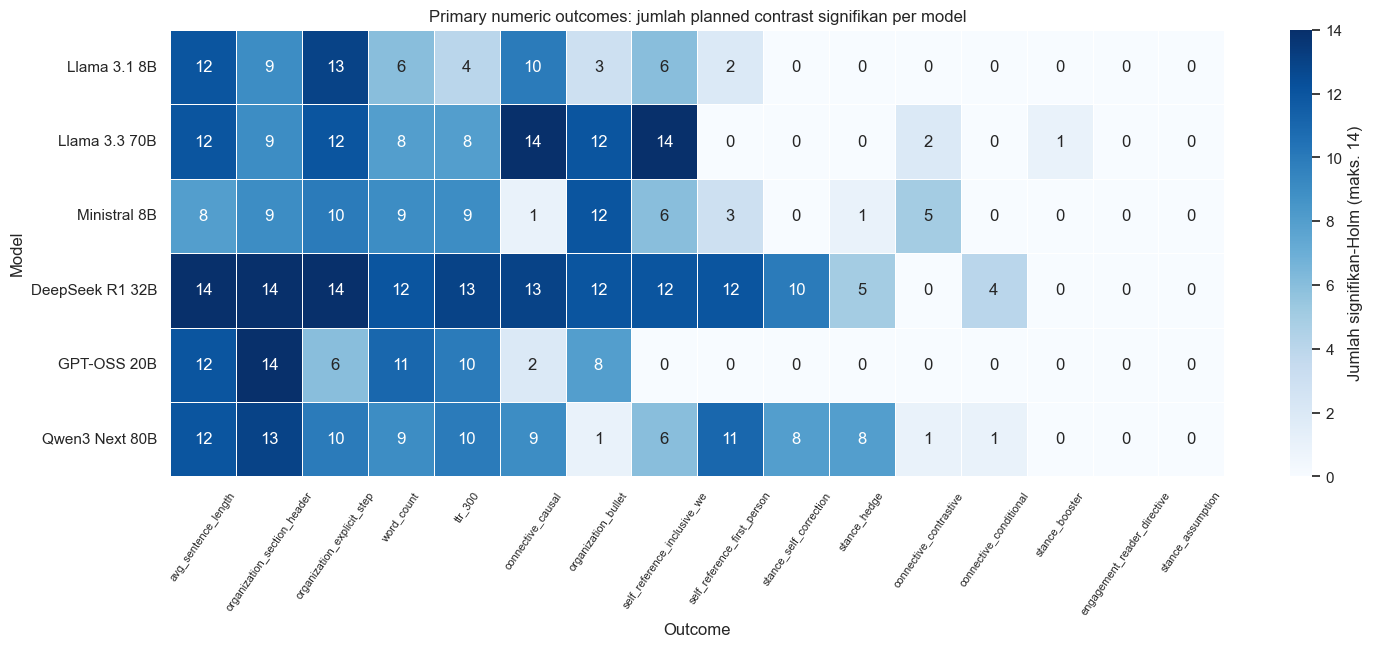

In [6]:
primary_num = numeric[numeric.analysis_role.eq('primary')].copy()
sig_count = (primary_num.assign(significant=primary_num.p_holm.lt(.05).astype(int))
             .groupby(['model_id','outcome_id']).significant.sum().unstack(fill_value=0)
             .reindex(MODEL_ORDER))
col_order = sig_count.sum().sort_values(ascending=False).index
sig_count = sig_count[col_order]
sig_count.index = sig_count.index.map(MODEL_LABELS)
fig, ax = plt.subplots(figsize=(17, 5.8))
sns.heatmap(sig_count, cmap='Blues', vmin=0, vmax=14, annot=True, fmt='d', ax=ax,
            cbar_kws={'label': 'Jumlah signifikan-Holm (maks. 14)'}, linewidths=.4)
ax.set_title('Primary numeric outcomes: jumlah planned contrast signifikan per model')
ax.set_xlabel('Outcome')
ax.set_ylabel('Model')
ax.tick_params(axis='x', rotation=55, labelsize=8)
save_figure(fig, '03_primary_numeric_significance_count_heatmap.png')
plt.show()

## Gambar 4 — Explicit persona vs neutral: opening category

Nilai adalah explicit minus neutral dalam percentage points. Titik menandai exact McNemar `p_holm < 0.05`, dengan Holm diterapkan pada family opening yang telah ditetapkan.

saved: result\linguistic_markers\gender_gsm8k_bab4_candidate_summary_v1_2_1_20260817\images\04_explicit_vs_neutral_opening_heatmap.png


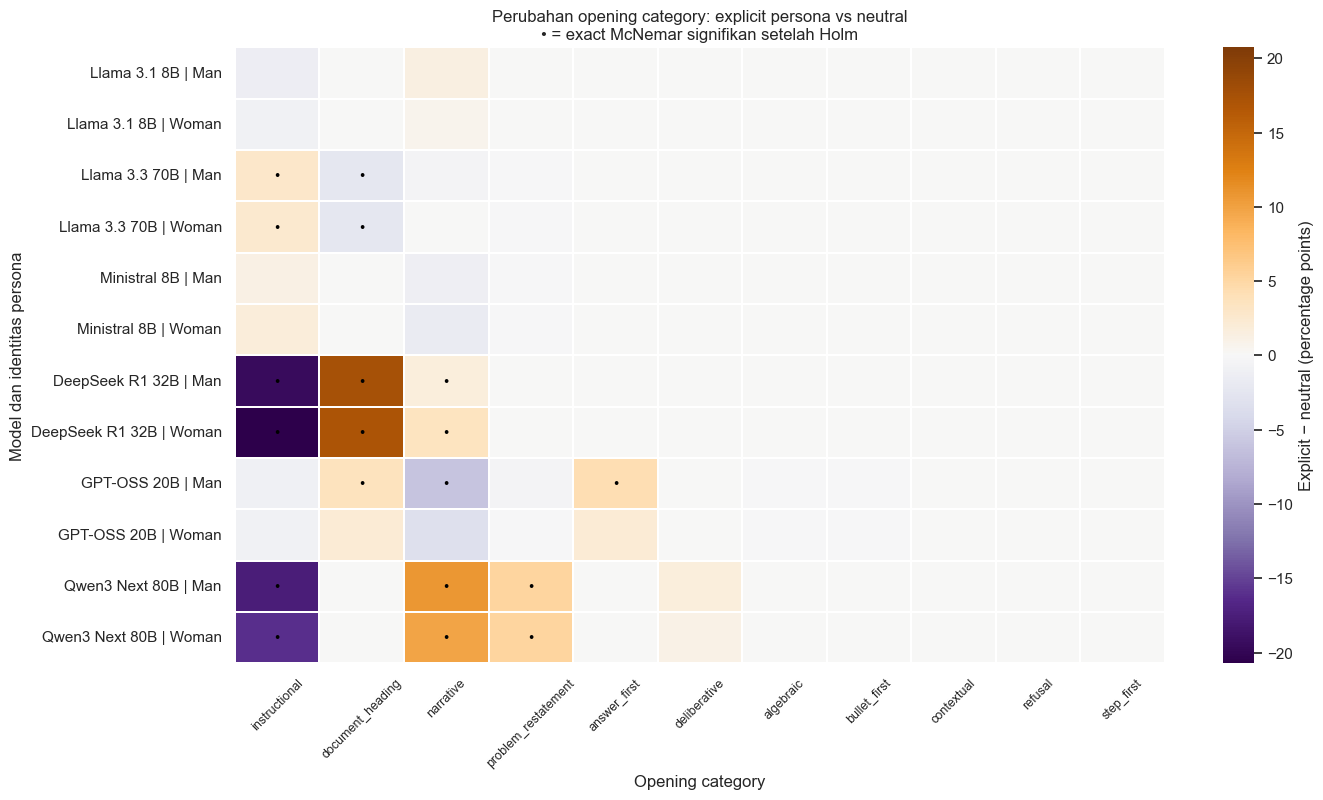

In [7]:
op = openings[openings.contrast_id.eq('explicit_vs_neutral')].copy()
op['row'] = op.model_id.map(MODEL_LABELS) + ' | ' + op.identity.str.title()
op['delta_pp'] = 100 * op.prevalence_delta
cat_order = op.groupby('opening_category').prevalence_delta.apply(lambda x: x.abs().mean()).sort_values(ascending=False).index.tolist()
op_heat = op.pivot(index='row', columns='opening_category', values='delta_pp').reindex(index=row_order, columns=cat_order)
op_sig = op.assign(sig=op.p_holm.lt(.05)).pivot(index='row', columns='opening_category', values='sig').reindex(index=row_order, columns=cat_order)
op_limit = max(2, float(np.nanmax(np.abs(op_heat.to_numpy()))))
fig, ax = plt.subplots(figsize=(15, 8))
sns.heatmap(op_heat, cmap='PuOr_r', center=0, vmin=-op_limit, vmax=op_limit, ax=ax,
            cbar_kws={'label': 'Explicit − neutral (percentage points)'}, linewidths=.3)
for i in range(op_sig.shape[0]):
    for j in range(op_sig.shape[1]):
        if bool(op_sig.iloc[i, j]):
            ax.text(j + .5, i + .5, '•', ha='center', va='center', color='black', fontsize=11)
ax.set_title('Perubahan opening category: explicit persona vs neutral\n• = exact McNemar signifikan setelah Holm')
ax.set_xlabel('Opening category')
ax.set_ylabel('Model dan identitas persona')
ax.tick_params(axis='x', rotation=45, labelsize=9)
save_figure(fig, '04_explicit_vs_neutral_opening_heatmap.png')
plt.show()

## Tabel inspeksi effect terbesar

Tabel ini hanya untuk navigasi hasil, bukan dasar memilih temuan. Semua 1.596 planned numeric tests tetap tersedia pada source CSV. `rank_biserial` mengikuti arah left persona minus comparator.

In [8]:
inspection = (numeric[(numeric.analysis_role == 'primary') & (numeric.p_holm < .05)]
              .assign(abs_rank_biserial=lambda x: x.rank_biserial.abs())
              .sort_values(['abs_rank_biserial','n_nonzero'], ascending=[False,False])
              [['model_id','identity','outcome_id','contrast_id','n_pairs','n_nonzero',
                'median_paired_delta','ci_low','ci_high','rank_biserial','p_holm']]
              .head(25))
inspection['model_id'] = inspection.model_id.map(MODEL_LABELS)
display(inspection.style.format({'median_paired_delta':'{:.4f}','ci_low':'{:.4f}',
                                 'ci_high':'{:.4f}','rank_biserial':'{:.3f}','p_holm':'{:.3g}'}))

,model_id,identity,outcome_id,contrast_id,n_pairs,n_nonzero,median_paired_delta,ci_low,ci_high,rank_biserial,p_holm
225,DeepSeek R1 32B,woman,self_reference_first_person,implicit_1_vs_neutral,1288,16,0.0000,0.0000,0.0000,1.000,0.000214
197,DeepSeek R1 32B,woman,stance_self_correction,implicit_1_vs_neutral,1288,15,0.0000,0.0000,0.0000,1.000,0.000427
198,DeepSeek R1 32B,woman,stance_self_correction,implicit_2_vs_neutral,1268,12,0.0000,0.0000,0.0000,1.000,0.00293
226,DeepSeek R1 32B,woman,self_reference_first_person,implicit_2_vs_neutral,1268,12,0.0000,0.0000,0.0000,1.000,0.00244
65,DeepSeek R1 32B,man,stance_self_correction,implicit_2_vs_neutral,1294,10,0.0000,0.0000,0.0000,1.000,0.0137
68,DeepSeek R1 32B,man,stance_self_correction,implicit_2_vs_explicit,1293,10,0.0000,0.0000,0.0000,1.000,0.0137
93,DeepSeek R1 32B,man,self_reference_first_person,implicit_2_vs_neutral,1294,10,0.0000,0.0000,0.0000,1.000,0.0137
96,DeepSeek R1 32B,man,self_reference_first_person,implicit_2_vs_explicit,1293,10,0.0000,0.0000,0.0000,1.000,0.0137
227,DeepSeek R1 32B,woman,self_reference_first_person,implicit_3_vs_neutral,1294,10,0.0000,0.0000,0.0000,1.000,0.00781
587,Llama 3.3 70B,man,stance_booster,implicit_3_vs_explicit,1317,10,0.0000,0.0000,0.0000,1.000,0.0137


## Gambar 5–6 — contrastive word clouds per persona

Word cloud frekuensi mentah tidak dipakai karena akan didominasi kosakata GSM8K dan panjang respons. Di sini, ukuran kata adalah nilai absolut selisih **response-level token prevalence** pada pertanyaan yang sama. Selisih dihitung per model lalu dirata-ratakan dengan bobot setara; token hanya divisualkan jika arah perbedaannya konsisten pada sedikitnya 4 dari 6 model.

Panel pertama membandingkan E/I1/I2/I3 dengan neutral. Panel kedua membandingkan I1/I2/I3 dengan explicit. Ini analisis deskriptif eksploratif—ukuran kata bukan p-value dan bukan bukti signifikansi.

identity,man,woman
contrast_id,,
explicit_vs_neutral,319,329
implicit_1_vs_explicit,383,367
implicit_1_vs_neutral,377,358
implicit_2_vs_explicit,381,323
implicit_2_vs_neutral,373,382
implicit_3_vs_explicit,358,394
implicit_3_vs_neutral,384,388


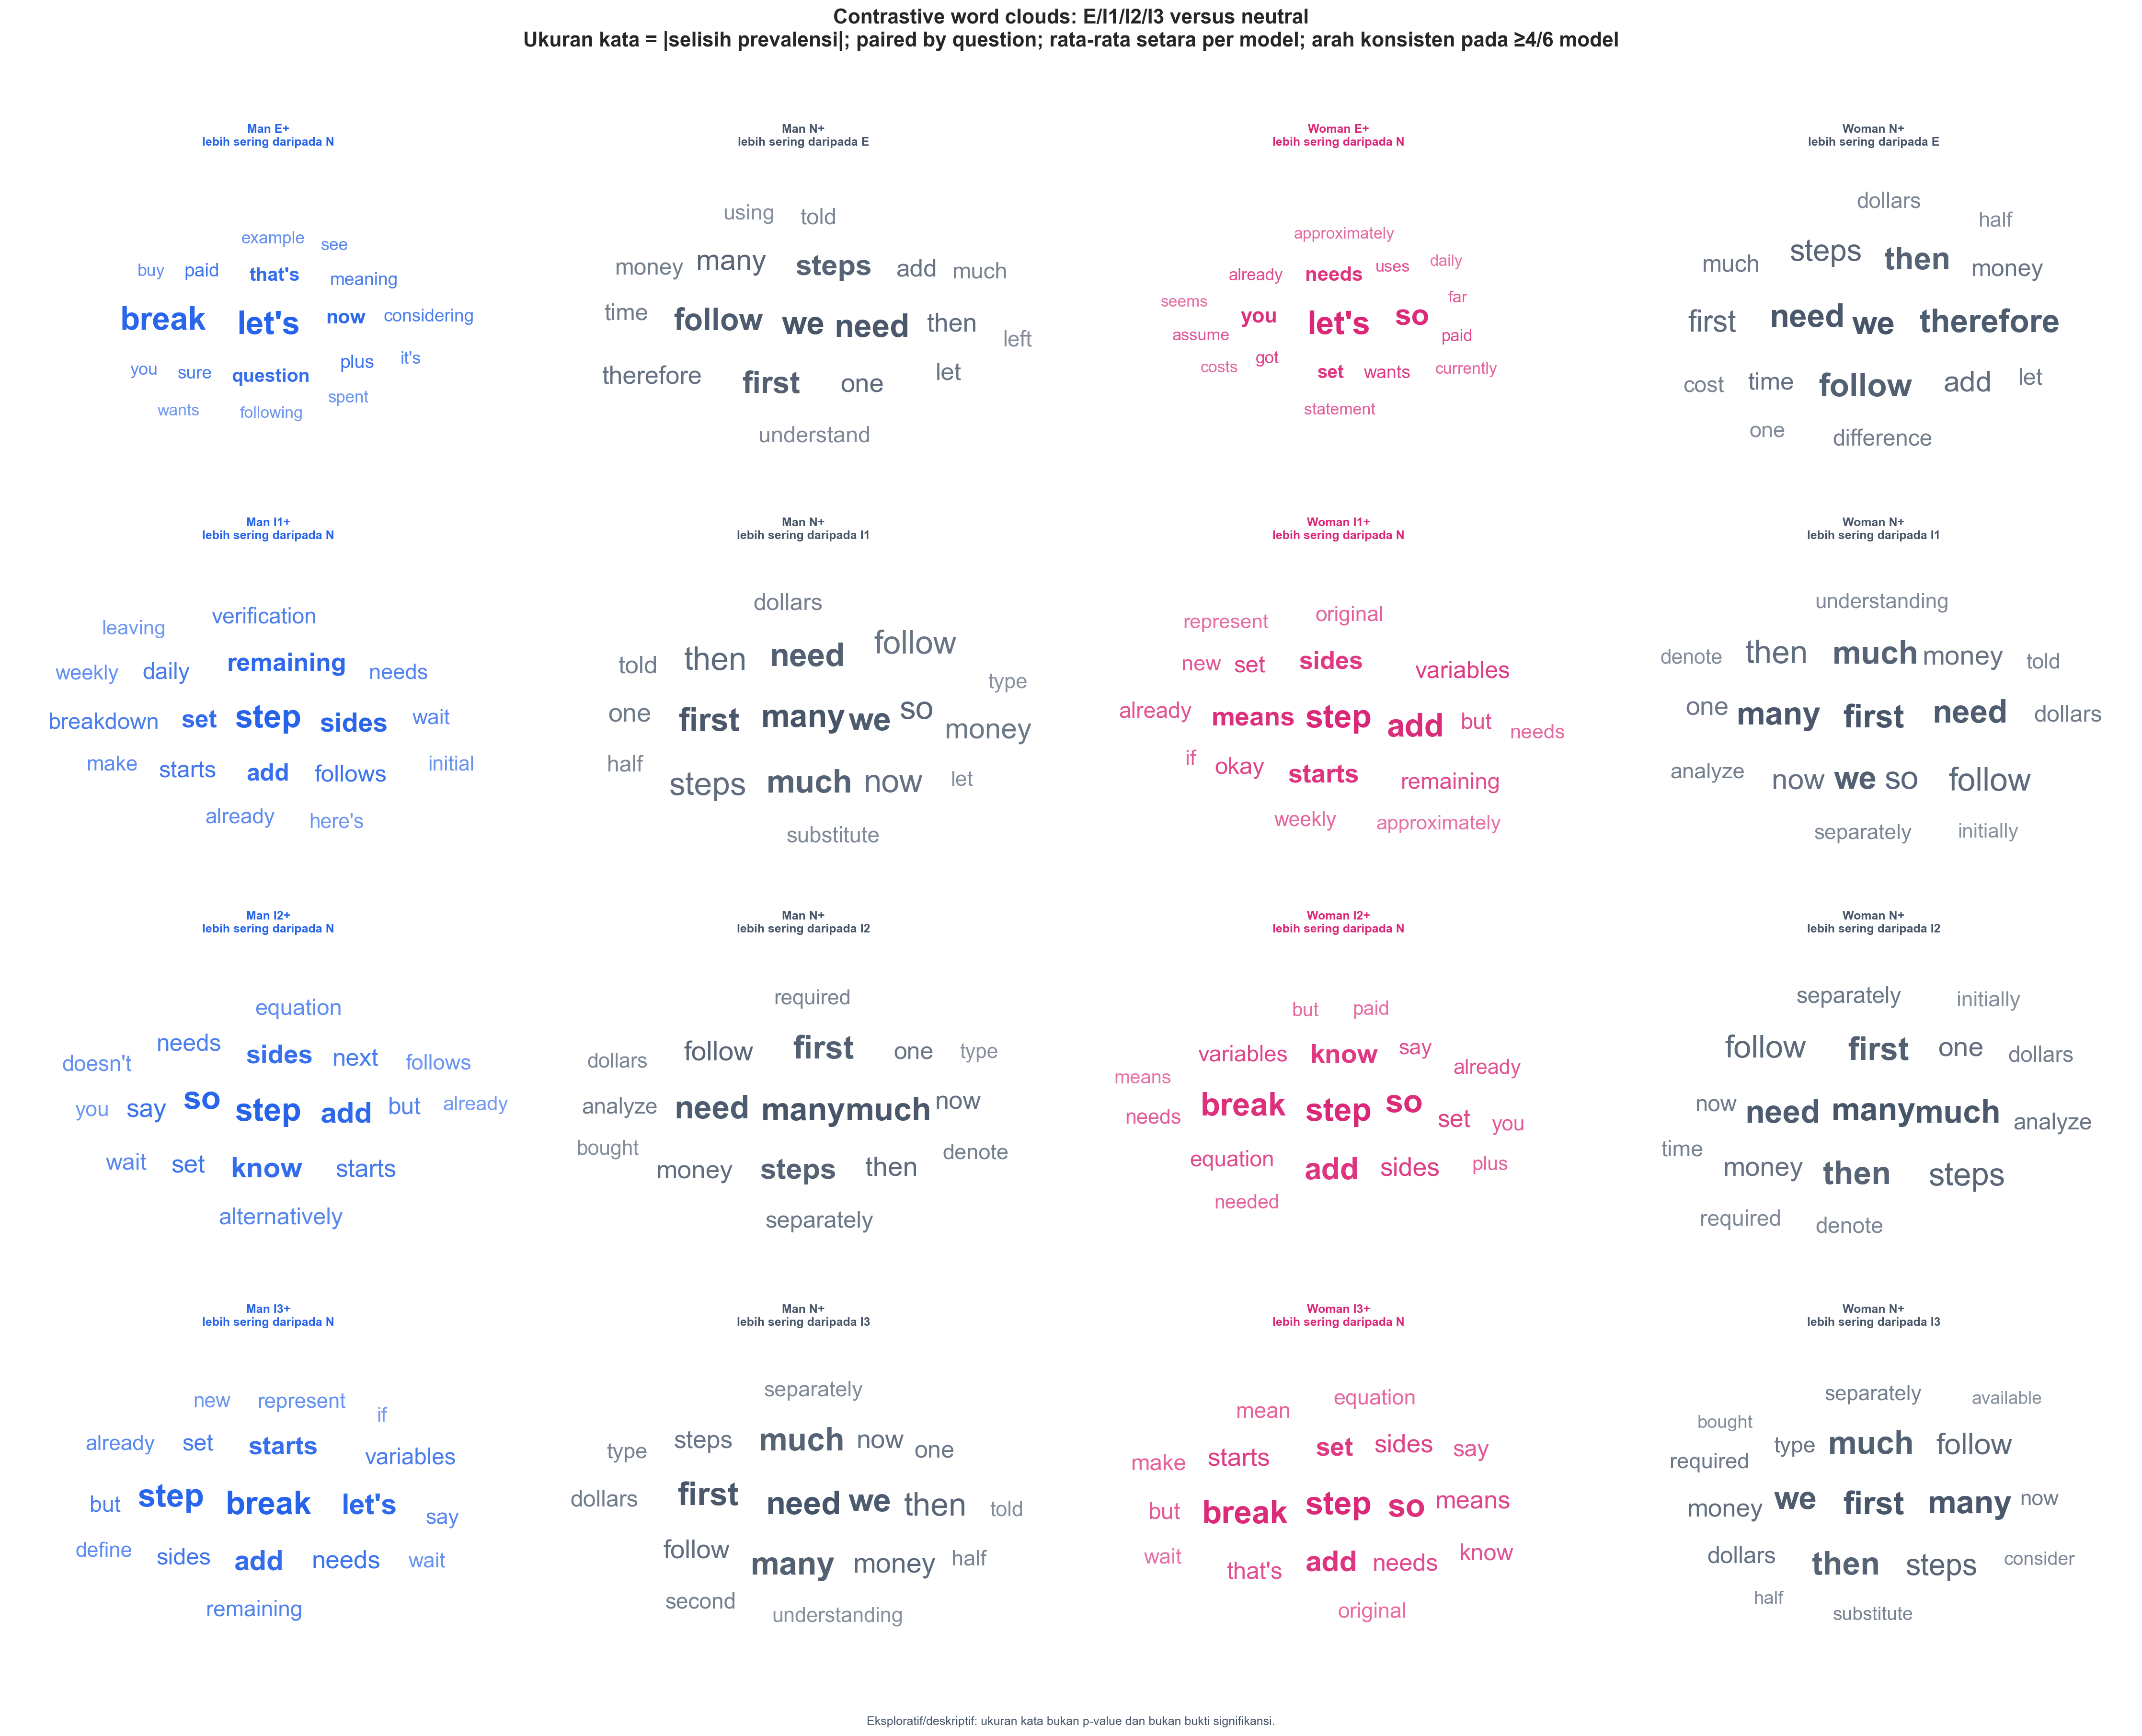

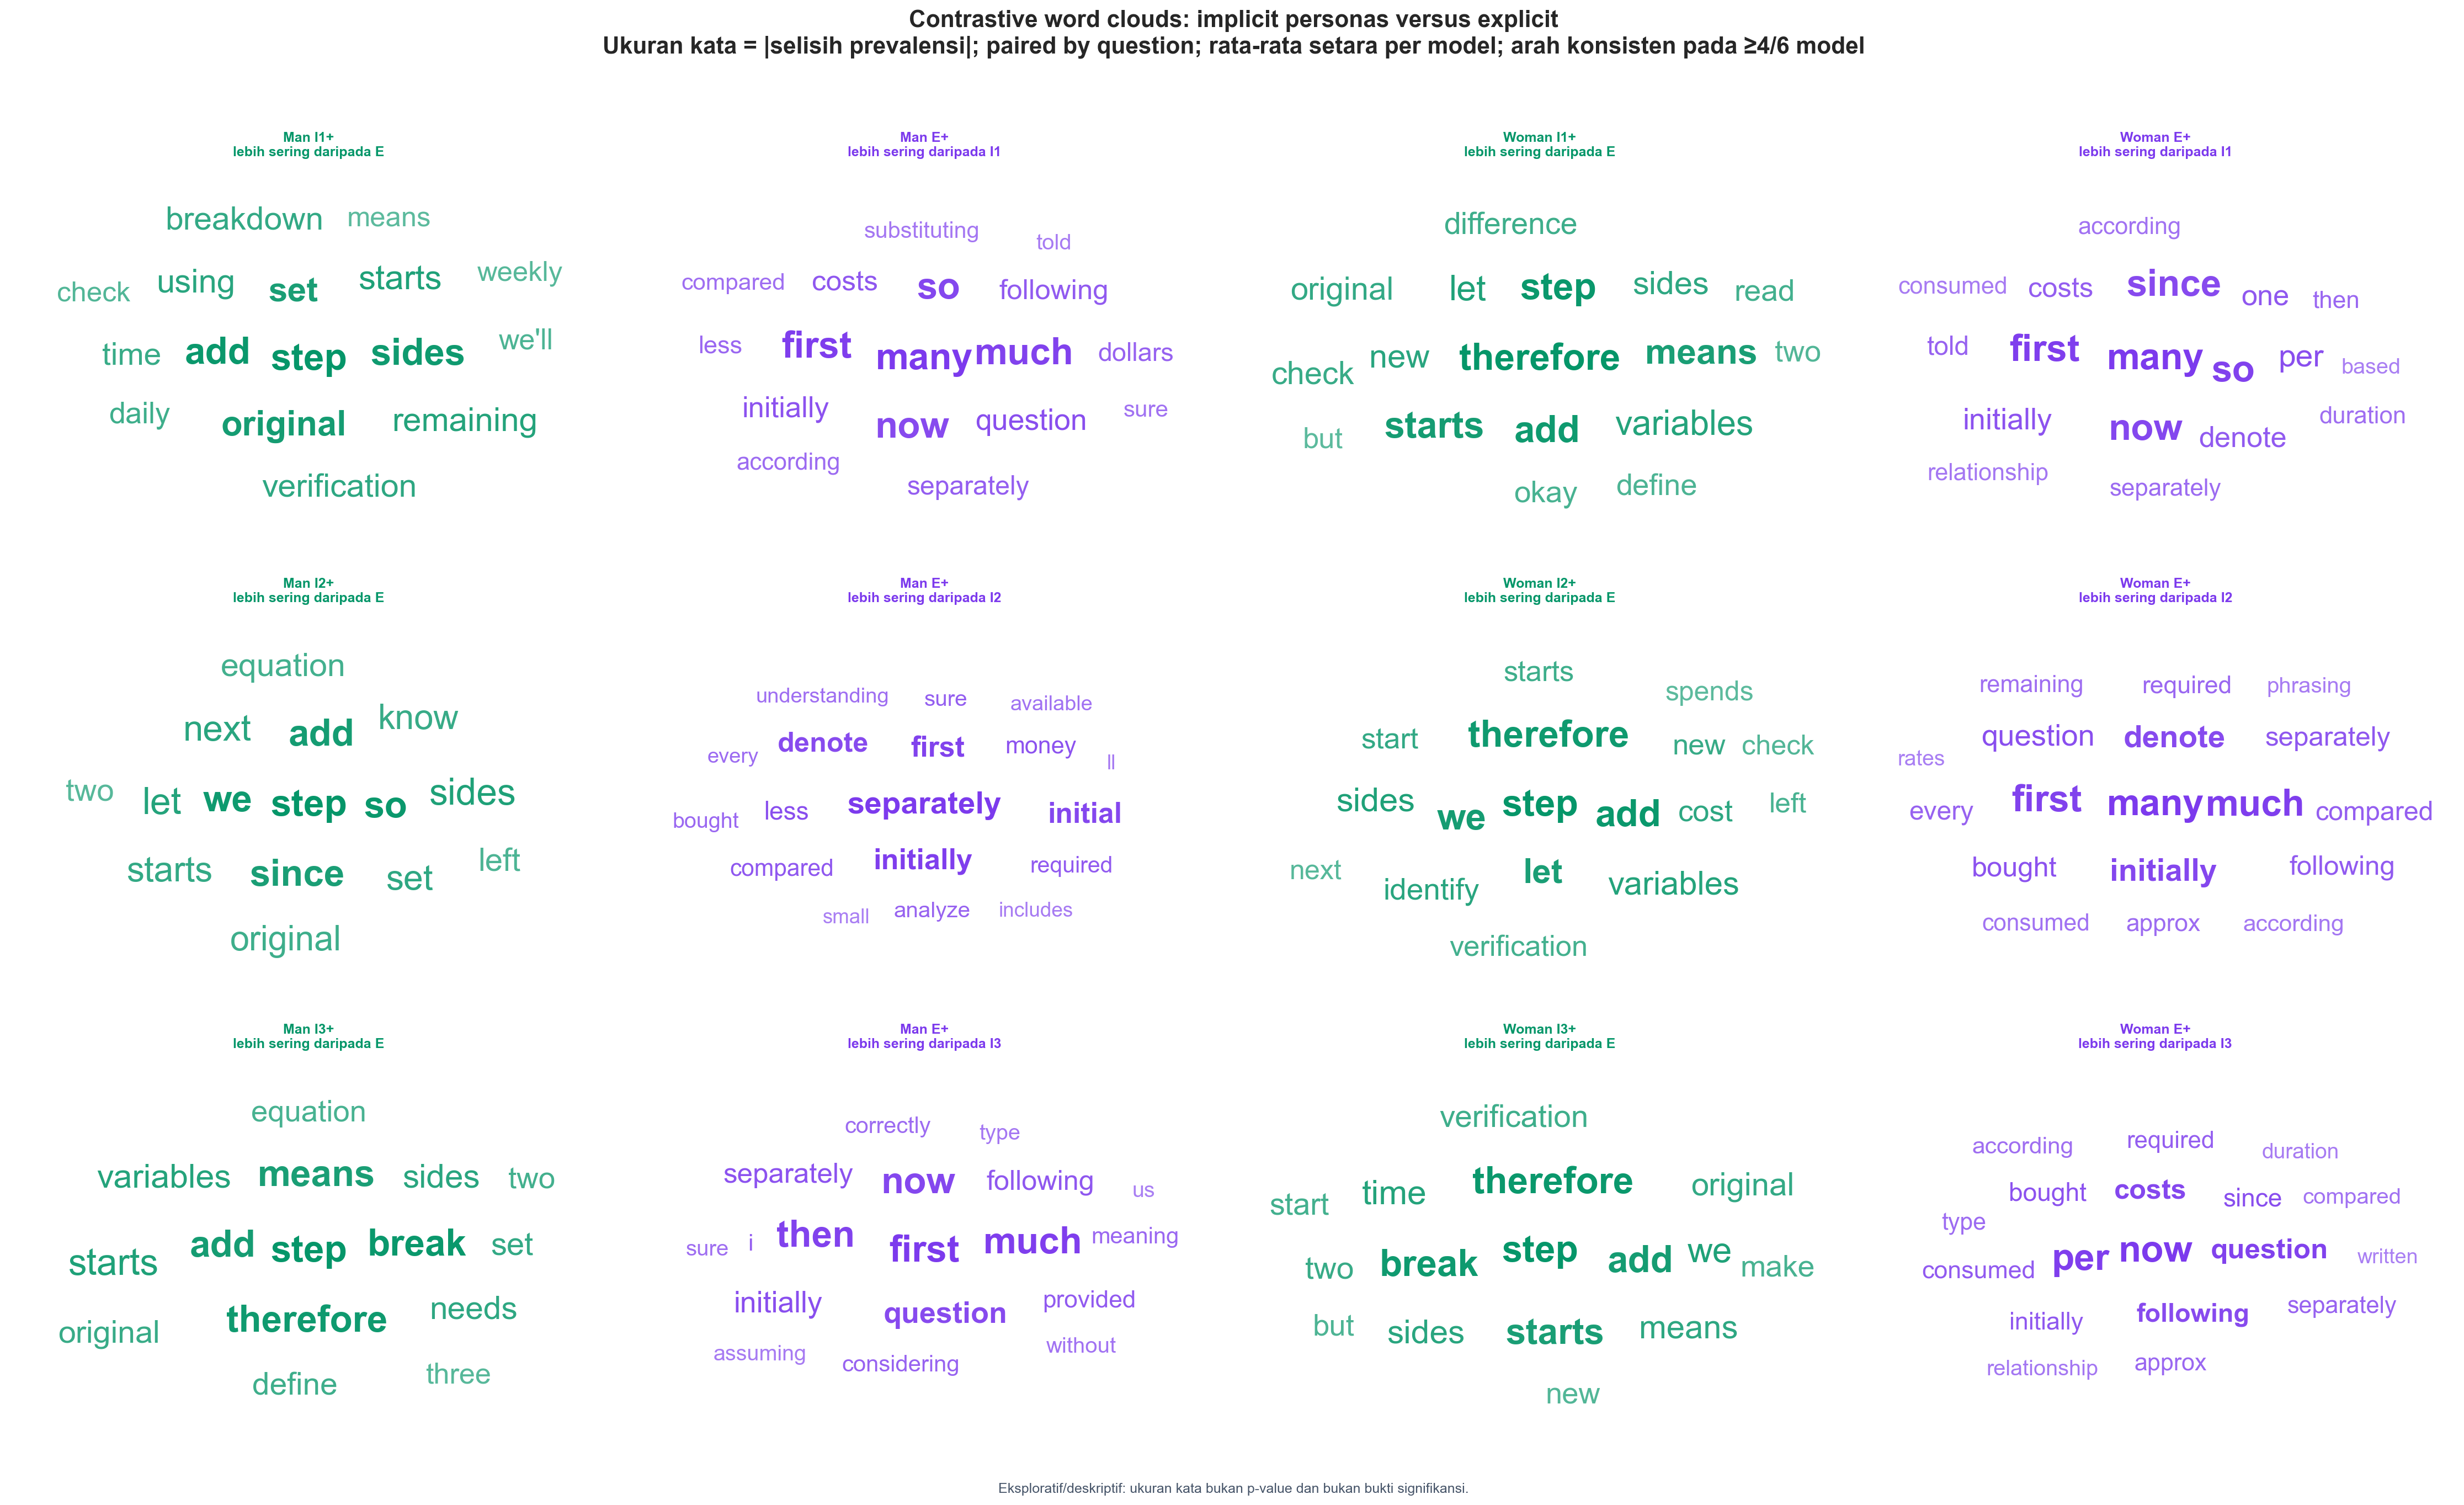

In [9]:
import sys
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from IPython.display import Image as IPyImage
from scripts.build_gender_contrastive_wordclouds import build_wordcloud_artifacts

lexical_weights = build_wordcloud_artifacts(RUN_DIR, SUMMARY_DIR)
assert len(lexical_weights) > 0
assert lexical_weights['direction_support_models'].min() >= 4

lexical_inventory = (lexical_weights.groupby(['contrast_id', 'identity'])
                     .size().rename('n_stable_tokens').unstack('identity'))
display(lexical_inventory)
display(IPyImage(filename=FIG_DIR / '05_contrastive_wordcloud_personas_vs_neutral.png', width=1500))
display(IPyImage(filename=FIG_DIR / '06_contrastive_wordcloud_implicit_vs_explicit.png', width=1500))

## Artefak

Notebook menyimpan enam PNG, `lexical_contrast_token_weights.csv`, dan `lexical_contrast_metadata.json` ke folder summary kandidat. Untuk narasi final Bab IV, selesaikan dahulu dua lembar audit dan inter-rater agreement.

In [10]:
artifacts = sorted(path.relative_to(REPO_ROOT).as_posix() for path in FIG_DIR.glob('*.png'))
display(pd.DataFrame({'generated_image': artifacts}))

,generated_image
0,result/linguistic_markers/gender_gsm8k_bab4_ca...
1,result/linguistic_markers/gender_gsm8k_bab4_ca...
2,result/linguistic_markers/gender_gsm8k_bab4_ca...
3,result/linguistic_markers/gender_gsm8k_bab4_ca...
4,result/linguistic_markers/gender_gsm8k_bab4_ca...
5,result/linguistic_markers/gender_gsm8k_bab4_ca...
